# Style Sheet

In [2]:
import matplotlib.pyplot as plt
import numpy as np
plt.style.use(r'style_sheets/base.mplstyle')

In [3]:
from pathlib import Path

def save_fig(fig=None, path="figure", *, dpi=600, transparent=True,
             pad_inches=0.05, editable_text=False, also=None):
    """Save a Matplotlib figure as a publication-ready SVG.

    Parameters
    ----------
    fig : Figure, optional
        Figure to save. Defaults to the current figure (plt.gcf()).
    path : str or Path
        Output path. A '.svg' suffix is added if missing.
    dpi : int
        Resolution of *embedded raster layers only* (e.g. imshow images);
        vector elements are unaffected. 600 keeps micrographs crisp.
    transparent : bool
        Transparent figure/axes background (lets the SVG sit on any page color).
    pad_inches : float
        Padding around the tight bounding box, in inches.
    editable_text : bool
        If True, keep glyphs as <text> (editable in Illustrator/Inkscape,
        smaller files). Ignored when text.usetex=True, since LaTeX emits paths.
    also : str or list of str, optional
        Extra formats to write alongside the SVG, e.g. 'pdf' or ['pdf', 'png'].
    """
    fig = fig or plt.gcf()
    path = Path(path).with_suffix(".svg")
    path.parent.mkdir(parents=True, exist_ok=True)

    if editable_text and not plt.rcParams.get("text.usetex", False):
        plt.rcParams["svg.fonttype"] = "none"

    kw = dict(dpi=dpi, transparent=transparent,
              bbox_inches="tight", pad_inches=pad_inches)

    fig.savefig(path, **kw)

    if also:
        for fmt in ([also] if isinstance(also, str) else also):
            fig.savefig(path.with_suffix(f".{fmt}"), **kw)

    return path

# Introduction Figures

# Newton Rings Equation

WindowsPath('Figures/NewtonRings.svg')

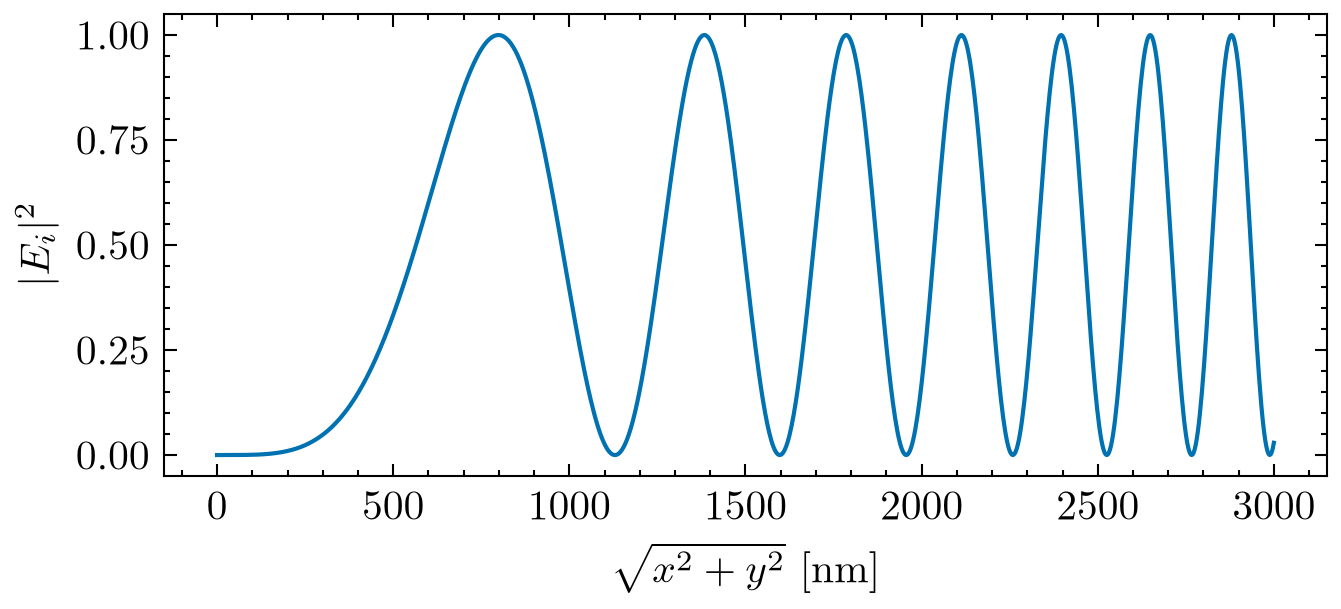

In [19]:
fig = plt.figure(figsize=(5,2))
ax = fig.add_subplot(111)

x_range = np.linspace(0, 3000, 1000) # each step is a nm

def NewtonRing(x, R_c, w):

    coef = x**2 * 2 * np.pi / (2 * R_c *w)
    return 1-(np.cos(coef))**2

ax.plot(x_range, NewtonRing(x_range, 45 * 10*(7), 405))
ax.set_ylabel(r'$|E_i|^2$')
ax.set_xlabel(r'$\sqrt{x^2 + y^2}$ [nm]')

save_fig(fig, r'Figures/NewtonRings.svg')
